In [1]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Training on:", device)

Training on: cuda


In [2]:
import numpy as np
import pandas as pd

x_crop = np.load("x_crop.npy")            # (N, 1, 224, 224), values 0-1
x_ctx  = np.load("x_ctx.npy")
df = pd.read_csv("df_with_paths.csv")     # labels, splits, patient IDs, paths
y = df["label"].values

print(x_crop.shape, x_ctx.shape, len(df))

(1696, 1, 224, 224) (1696, 1, 224, 224) 1696


In [3]:
is_train = (df["split"] == "train").values
is_val   = (df["split"] == "val").values
is_test  = (df["split"] == "test").values

MEAN = x_crop[is_train].mean()      # from TRAINING crops only
STD  = x_crop[is_train].std()
print(f"training mean {MEAN:.3f}, std {STD:.3f}")

train_aug = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomVerticalFlip(),
    v2.RandomAffine(degrees=25, scale=(0.8, 1.2)),   # rotation +/-25 degrees, zoom 0.8-1.2
    v2.ColorJitter(brightness=0.2),                  # brightness shift
])

class CropDataset(Dataset):
    def __init__(self, x, y, augment=False):
        self.x = torch.from_numpy(x)
        self.y = torch.from_numpy(y).float()
        self.augment = augment
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        img = self.x[i]                    # (1, 224, 224), values 0-1
        if self.augment:
            img = train_aug(img)           # training only
        img = (img - MEAN) / STD           # normalise
        return img, self.y[i]

train_ds = CropDataset(x_crop[is_train], y[is_train], augment=True)
val_ds = CropDataset(x_crop[is_val],   y[is_val])
test_ds = CropDataset(x_crop[is_test],  y[is_test])
print(len(train_ds), len(val_ds), len(test_ds))

training mean 0.478, std 0.249
1177 350 169


In [4]:
class ANN(nn.Module):
    def __init__(self, hidden1=256, hidden2=64, dropout=0.3):
        super(ANN, self).__init__()
        self.name = "ann{}_{}".format(hidden1, hidden2)
        self.pool = nn.AdaptiveAvgPool2d(64)           # 224x224 -> 64x64 (no weights)
        self.layer1 = nn.Linear(64 * 64, hidden1)      # 4,096 -> 256
        self.layer2 = nn.Linear(hidden1, hidden2)      # 256 -> 64
        self.layer3 = nn.Linear(hidden2, 1)            # 64 -> 1
        self.dropout = nn.Dropout(dropout)

    def forward(self, img):
        small = self.pool(img)
        flattened = small.view(-1, 64 * 64)
        activation1 = self.dropout(F.relu(self.layer1(flattened)))
        activation2 = self.dropout(F.relu(self.layer2(activation1)))
        activation3 = self.layer3(activation2)
        return activation3.squeeze(1)

net = ANN()
print(net.name, "| parameters:", sum(p.numel() for p in net.parameters()))

ann256_64 | parameters: 1065345


In [5]:
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

METRICS = ["loss", "auroc", "accuracy", "sensitivity", "specificity", "precision", "f1"]

def compute_metrics(labels, probs, threshold=0.5):
    """All success metrics (and confusion-matrix counts) from true labels and predicted probabilities."""
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0     # malignant masses caught
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0     # benign masses correctly cleared
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0       # "malignant" predictions that are right
    f1 = 2 * precision * sensitivity / (precision + sensitivity) if (precision + sensitivity) > 0 else 0.0
    return {"auroc": roc_auc_score(labels, probs),
            "accuracy": (tp + tn) / len(labels),
            "sensitivity": sensitivity, "specificity": specificity,
            "precision": precision, "f1": f1,
            "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn)}

In [ ]:
def evaluate(net, loader, criterion):
    """Loss and all success metrics on a dataset, without training."""
    net.eval()
    total_loss, total = 0.0, 0
    all_probs, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = net(inputs)
            total_loss += criterion(outputs, labels).item() * len(labels)
            total += len(labels)
            all_probs.append(torch.sigmoid(outputs).cpu()); all_labels.append(labels.cpu())
    results = compute_metrics(torch.cat(all_labels).numpy(), torch.cat(all_probs).numpy())
    results["loss"] = total_loss / total
    return results

def train_net(net, train_ds, val_ds, batch_size=32, learning_rate=0.001, num_epochs=50):
    torch.manual_seed(1)
    net = net.to(device)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=0)

    # class-weighted BCE: malignant errors weighted by #benign / #malignant
    n_pos = train_ds.y.sum().item()
    n_neg = len(train_ds) - n_pos
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([n_neg / n_pos], device=device))
    optimizer = optim.Adam(net.parameters(), lr=learning_rate)       # every layer trains

    history = {"train": [], "val": []}          # one dictionary of results per epoch
    start_time = time.time()
    for epoch in range(num_epochs):
        # --- train ---
        net.train()
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        # --- measure on train and validation ---
        train_res = evaluate(net, train_loader, criterion)
        val_res = evaluate(net, val_loader, criterion)
        history["train"].append(train_res)
        history["val"].append(val_res)
        print("Epoch {}: Train AUROC {:.3f}, loss {:.3f} | Val AUROC {:.3f}, loss {:.3f}".format(
            epoch + 1, train_res["auroc"], train_res["loss"], val_res["auroc"], val_res["loss"]))

    print("Finished training in {:.1f} seconds".format(time.time() - start_time))
    return history


MODEL_NAME = "mlp"
net = ANN(hidden1=256, hidden2=64, dropout=0.3)        # fresh model every time you run this cell
print("parameters:", sum(p.numel() for p in net.parameters()))   # 1,065,345
history = train_net(net, train_ds, val_ds, batch_size=32, learning_rate=0.001, num_epochs=50)

parameters: 1065345
Epoch 0: Train AUROC 0.557, loss 0.749 | Val AUROC 0.627, loss 0.741
Epoch 1: Train AUROC 0.500, loss 0.760 | Val AUROC 0.464, loss 0.769
Epoch 2: Train AUROC 0.534, loss 0.749 | Val AUROC 0.588, loss 0.746
Epoch 3: Train AUROC 0.550, loss 0.750 | Val AUROC 0.473, loss 0.763
Epoch 4: Train AUROC 0.559, loss 0.750 | Val AUROC 0.573, loss 0.752
Epoch 5: Train AUROC 0.540, loss 0.749 | Val AUROC 0.562, loss 0.747
Epoch 6: Train AUROC 0.598, loss 0.740 | Val AUROC 0.574, loss 0.747
Epoch 7: Train AUROC 0.565, loss 0.747 | Val AUROC 0.590, loss 0.746
Epoch 8: Train AUROC 0.559, loss 0.747 | Val AUROC 0.556, loss 0.755
Epoch 9: Train AUROC 0.565, loss 0.743 | Val AUROC 0.615, loss 0.745
Epoch 10: Train AUROC 0.558, loss 0.749 | Val AUROC 0.593, loss 0.750
Epoch 11: Train AUROC 0.573, loss 0.749 | Val AUROC 0.645, loss 0.747
Epoch 12: Train AUROC 0.582, loss 0.750 | Val AUROC 0.604, loss 0.752
Epoch 13: Train AUROC 0.555, loss 0.748 | Val AUROC 0.627, loss 0.744
Epoch 14: 

Best epoch (highest validation AUROC): 42
             train  validation
loss         0.734       0.723
auroc        0.620       0.658
accuracy     0.567       0.551
sensitivity  0.779       0.801
specificity  0.388       0.326
precision    0.517       0.518
f1           0.622       0.629


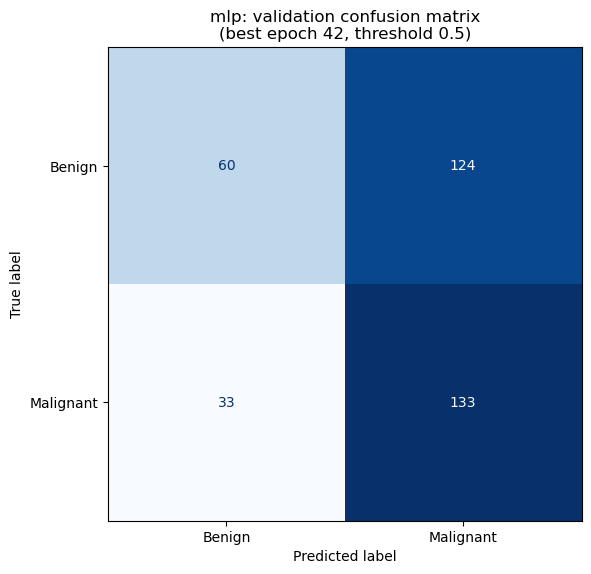

In [10]:
val_aurocs = [r["auroc"] for r in history["val"]]
best = int(np.argmax(val_aurocs))                          # AUROC picks the epoch
best_val = history["val"][best]
best_train = history["train"][best]

print("Best epoch (highest validation AUROC):", best + 1)
results = pd.DataFrame({"train": [best_train[m] for m in METRICS],
                        "validation": [best_val[m] for m in METRICS]}, index=METRICS)
print(results.round(3).to_string())
results.to_csv("{}_results.csv".format(MODEL_NAME))       # saved for comparing with the two-stream model

# confusion matrix of that same epoch
cm = np.array([[best_val["tn"], best_val["fp"]],
               [best_val["fn"], best_val["tp"]]])
disp = ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("{}: validation confusion matrix\n(best epoch {}, threshold 0.5)".format(MODEL_NAME, best + 1))
plt.tight_layout(); plt.savefig("{}_confusion_matrix.png".format(MODEL_NAME), dpi=150); plt.show()

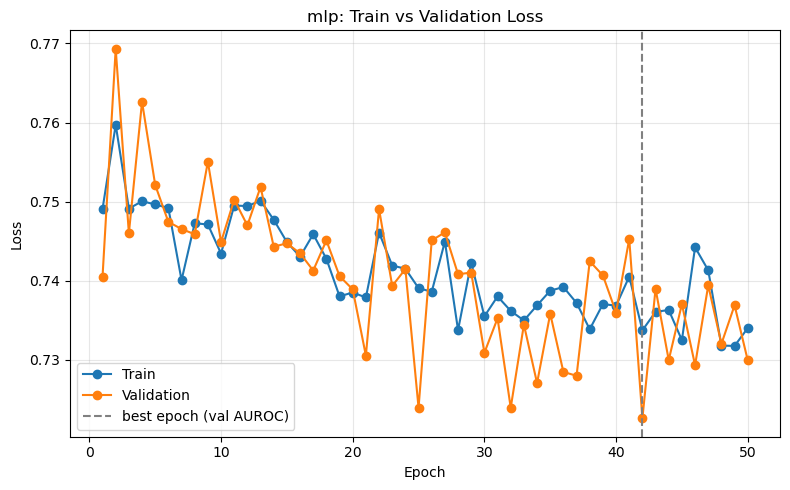

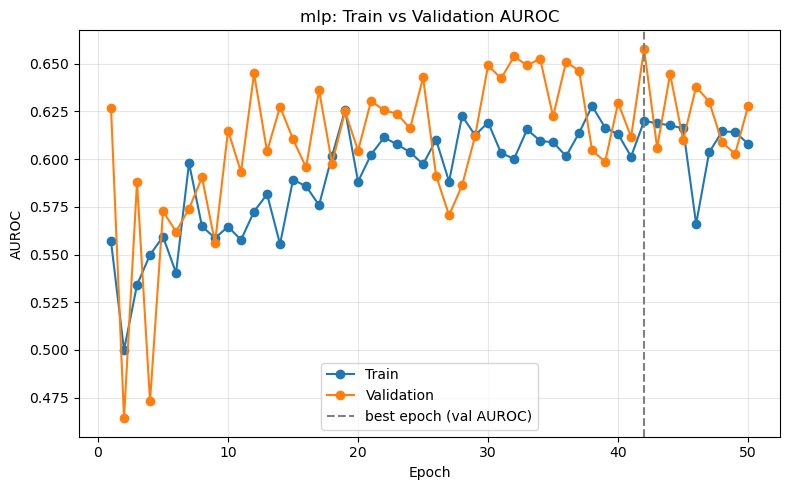

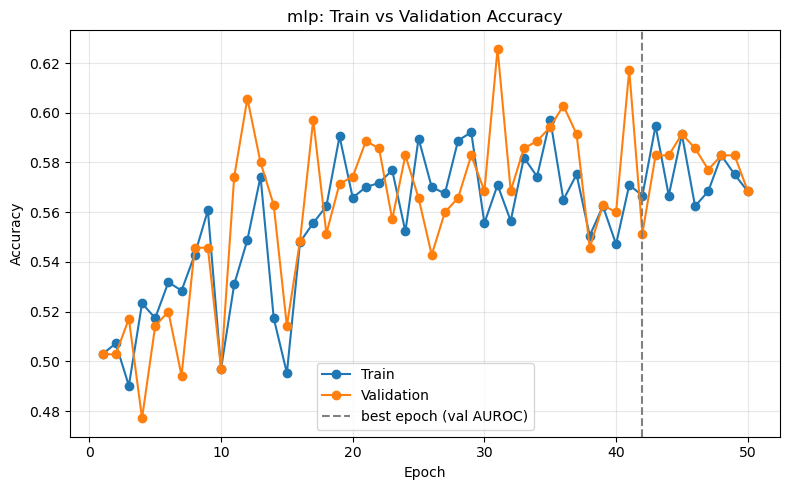

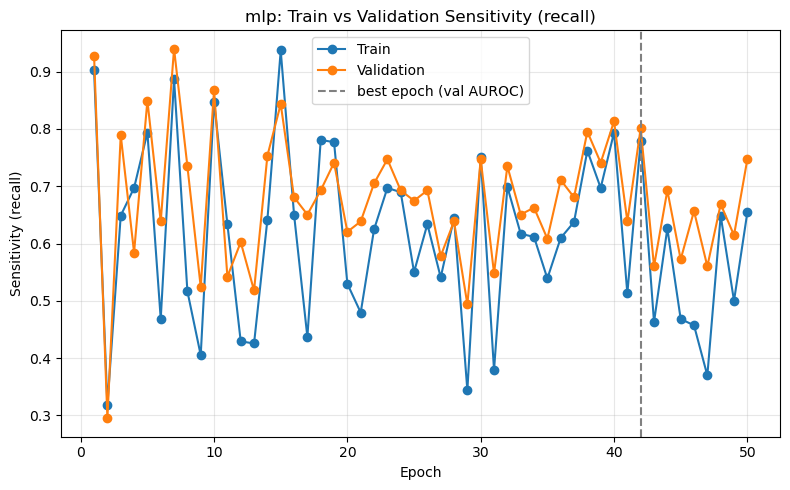

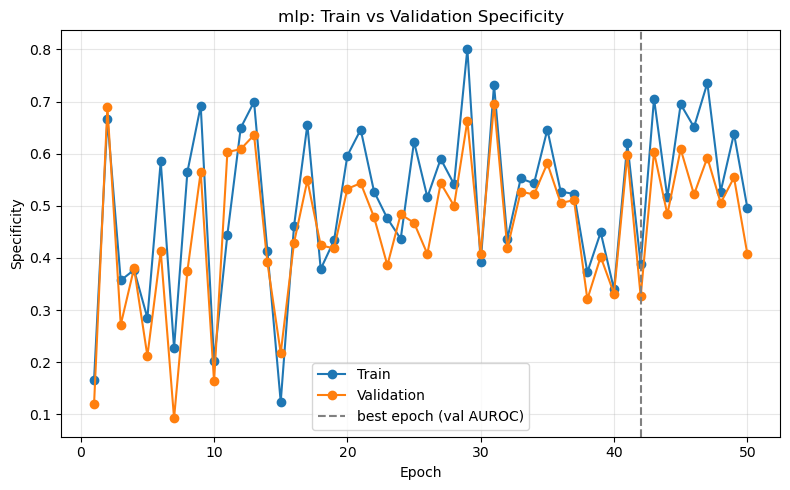

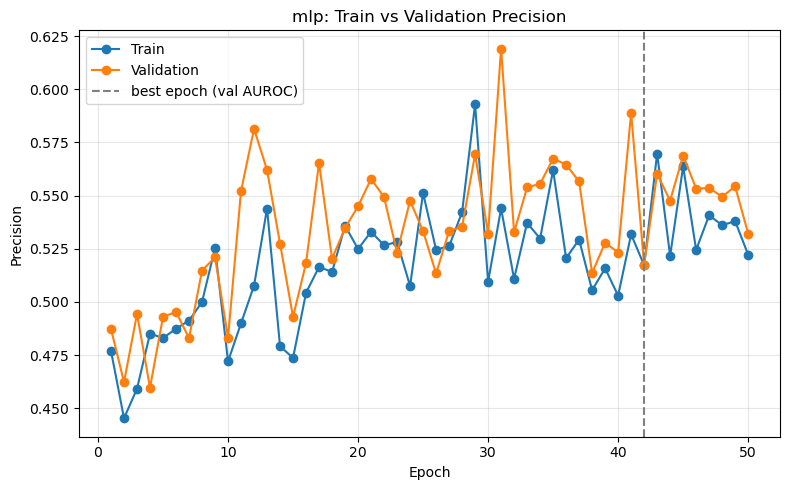

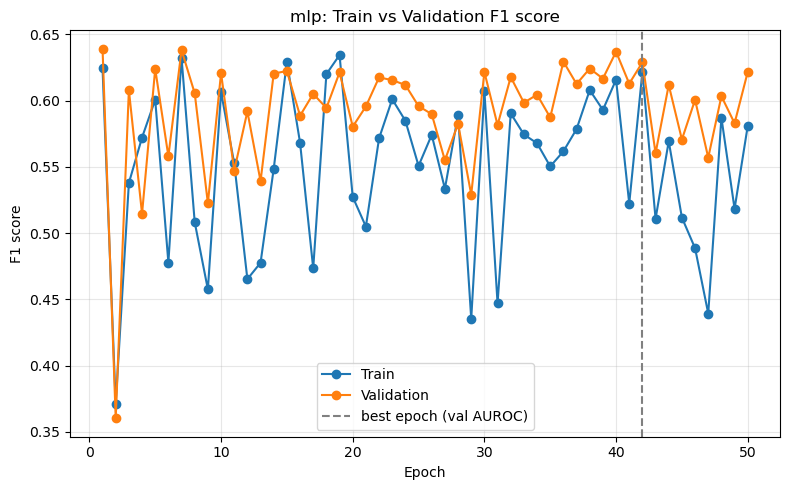

In [11]:
epochs = range(1, len(history["train"]) + 1)
titles = {"loss": "Loss", "auroc": "AUROC", "accuracy": "Accuracy", "sensitivity": "Sensitivity (recall)",
          "specificity": "Specificity", "precision": "Precision", "f1": "F1 score"}

for m in METRICS:
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, [r[m] for r in history["train"]], marker="o", label="Train")
    plt.plot(epochs, [r[m] for r in history["val"]], marker="o", label="Validation")
    plt.axvline(best + 1, color="gray", linestyle="--", label="best epoch (val AUROC)")
    plt.title("{}: Train vs Validation {}".format(MODEL_NAME, titles[m]))
    plt.xlabel("Epoch"); plt.ylabel(titles[m])
    plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
    plt.savefig("{}_{}.png".format(MODEL_NAME, m), dpi=150); plt.show()

In [12]:
print("=" * 60)
print("{}  |  best epoch: {} of {}  (chosen by validation AUROC)".format(
    MODEL_NAME, best + 1, len(history["val"])))
print("Validation AUROC {:.3f} | accuracy {:.3f} | sensitivity {:.3f} | specificity {:.3f} | F1 {:.3f}".format(
    best_val["auroc"], best_val["accuracy"], best_val["sensitivity"], best_val["specificity"], best_val["f1"]))
print("=" * 60)

mlp  |  best epoch: 42 of 50  (chosen by validation AUROC)
Validation AUROC 0.658 | accuracy 0.551 | sensitivity 0.801 | specificity 0.326 | F1 0.629
